# Pgx's Connect Four and Othello in expex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/main/examples/notebooks/pgx.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/main/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

Ports of two games of [Pgx](https://github.com/sotetsuk/pgx) to expex:
[`examples/pgx/connect_four.py`](../pgx/connect_four.py) and
[`examples/pgx/othello.py`](../pgx/othello.py). Pgx writes the rules as array programs (a flat
board, a table of all 69 four-in-a-row index tuples, `lax.cond`s over lambdas). The ports write
one game as one `@expex.struct` with plain Python: `board[row, col] = self.color`, a `while`
loop that walks from the new stone, `if self.terminated:`. A batch of games maps over the keys.

This notebook plays random games, shows what expex reads from the annotations, checks every
state against Pgx's saved games, and times it.

In [1]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "main"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO))
sys.path.insert(0, str(REPO / "examples" / "pgx"))
print("Python", sys.version.split()[0], "| examples from", REPO.name)

Python 3.14.6 | examples from vigilant-barnacle


In [2]:
import inspect
import time

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np

import expex
import connect_four  # examples/pgx/connect_four.py
import othello  # examples/pgx/othello.py
from connect_four import ConnectFour
from othello import Othello

print(inspect.getsource(ConnectFour.drop))
print(inspect.getsource(connect_four.line_length))

    def drop(self, col: i32) -> "ConnectFour":
        """Drop a stone of the colour to move into column `col`."""
        board = self.board
        row = Rows - 1 - (board[:, col] != EMPTY).sum()
        board[row, col] = self.color
        won = False
        for dr, dc in DIRECTIONS:
            won = won or line_length(board, row, col, dr, dc) >= 4
        rewards = jnp.zeros(Players)
        if won:
            rewards = -jnp.ones(Players)
            rewards[self.current_player] = 1.0  # the player who just moved
        legal = (board != EMPTY).sum(Rows) < Rows
        return self.replace(
            current_player=1 - self.current_player,
            color=1 - self.color,
            board=board,
            winner=self.color if won else -1,
            rewards=rewards,
            terminated=won or not legal.any(),
            legal_action_mask=legal,
        )

@expex.fn
def line_length(board: i32[Rows, Cols], row: i32, col: i32, dr: int, dc: int) -> i32:
    """How many st

## The annotated signatures

Every typed function and method of both games, as expex reads it:

In [3]:
def signature(f):
    owner = f.name.rpartition(".")[0]
    return f"{owner}.{f.signature}" if owner else f.signature


for module in (connect_four, othello):
    for report in expex.prove(module):
        print(f"{module.__name__:13} {signature(report.fn)}")

connect_four  ConnectFour.new(key: Key) -> ConnectFour
connect_four  ConnectFour.step(self: ConnectFour, action: i32[()]) -> ConnectFour
connect_four  ConnectFour.drop(self: ConnectFour, col: i32[()]) -> ConnectFour
connect_four  ConnectFour.observe(self: ConnectFour) -> Bool[Rows, Cols, Players]
connect_four  line_length(board: i32[Rows, Cols], row: i32[()], col: i32[()], dr: int, dc: int) -> i32[()]
connect_four  random_games(key: Key, games: int, moves: int) -> tuple[Batch[ConnectFour, games], f32[games, Players]]


othello       Othello.new(key: Key) -> Othello
othello       Othello.step(self: Othello, action: i32[()]) -> Othello
othello       Othello.play(self: Othello, action: i32[()]) -> Othello
othello       Othello.observe(self: Othello) -> Bool[Side, Side, Players]
othello       landings() -> tuple[Bool[Steps, Cells], Bool[Steps, Cells]]
othello       shift(x: Bool[Cells], dr: i32[()], dc: i32[()]) -> Bool[Cells]
othello       ray(start: Bool[Cells], through: Bool[Cells], dr: i32[()], dc: i32[()]) -> Bool[Cells]
othello       legal_moves(mine: Bool[Cells], theirs: Bool[Cells]) -> Bool[Actions]
othello       random_games(key: Key, games: int, moves: int) -> tuple[Batch[Othello, games], f32[games, Players]]


`expex.debug.shapes` shows the shape of every line of a move, for all sizes at once:

In [4]:
print(expex.debug.shapes(ConnectFour.drop))

drop(self: ConnectFour, col: i32[()]) -> ConnectFour   [symbolic ]
   86 |     def drop(self, col: i32) -> "ConnectFour":
   87 |         """Drop a stone of the colour to move into column `col`."""
   88 |         board = self.board                                                 # board: i32[6, 7]
   89 |         row = Rows - 1 - (board[:, col] != EMPTY).sum()                    # row: i32[()]
   90 |         board[row, col] = self.color                                       # board: i32[6, 7]
   91 |         won = False
   92 |         for dr, dc in DIRECTIONS:                                          # won: Bool[()]
   93 |             won = won or line_length(board, row, col, dr, dc) >= 4         # won: Bool[()]
   94 |         rewards = jnp.zeros(Players)                                       # rewards: f32[2]
   95 |         if won:                                                            # rewards: f32[2]
   96 |             rewards = -jnp.ones(Players)                        

## Run it

1000 games of each, with uniformly random legal moves, in one jitted call per game:

In [5]:
for game, module, moves in ((ConnectFour, connect_four, 42), (Othello, othello, 64)):
    state, returns = module.random_games(jr.key(0), 1000, moves)
    first = returns[:, 0]
    print(f"{game.__name__}: player 0 won {(first > 0).sum()}, lost {(first < 0).sum()}, drew {(first == 0).sum()}")

state, _ = connect_four.random_games(jr.key(0), 1000, 42)
print("\nConnect Four, game 0 at the end:")
for row in state.board[0]:
    print("  " + " ".join(".xo"[int(v) + 1] for v in row))

ConnectFour: player 0 won 512, lost 488, drew 0


Othello: player 0 won 481, lost 461, drew 58

Connect Four, game 0 at the end:
  . . . . . . .
  . x . . . . .
  . x . o . . .
  x x o x . . x
  o x o o . . o
  o o x o . x x


The `if`s became `lax.cond`s, the `while` a `lax.while_loop`, and Othello's loop over the
eight directions one `lax.scan`:

In [6]:
print("ConnectFour.step: ", ConnectFour.step.flow)
print("line_length:      ", connect_four.line_length.flow)
print("Othello.play:     ", Othello.play.flow)

ConnectFour.step:  {74: 'if -> lax.cond', 78: 'if -> lax.cond', 82: 'if -> lax.cond'}
line_length:       {118: 'for -> unrolled (iterating over a tuple)', 120: 'while -> lax.while_loop'}
Othello.play:      {102: 'for -> lax.scan (carries flips)', 104: 'if -> lax.cond', 111: 'if -> lax.cond'}


## What the annotations give

**Proofs** for every size, without data:

In [7]:
expex.prove(connect_four)

ok    connect_four.ConnectFour.new
ok    connect_four.ConnectFour.step
ok    connect_four.ConnectFour.drop
ok    connect_four.ConnectFour.observe
ok    connect_four.line_length
ok    connect_four.random_games

6 functions: 6 proved

In [8]:
expex.prove(othello)

ok    othello.Othello.new
ok    othello.Othello.step
ok    othello.Othello.play
ok    othello.Othello.observe
ok    othello.landings
ok    othello.shift
ok    othello.ray
ok    othello.legal_moves
ok    othello.random_games

9 functions: 9 proved

**Cost** of one move, and **a summary** of one game's state (game 0 of the batch):

In [9]:
print(expex.cost(ConnectFour.step))
print(expex.cost(Othello.step))

ConnectFour.step   (sizes: Rows (= 6), Cols (= 7), Players (= 2))
  flops        684   = 684 FLOP
  parameters   141   = 141
  largest      bool[6,7,2] (84 elements)
  note: while loop at examples/pgx/connect_four.py:122 (line_length): trip count unknown, one iteration counted
Othello.step   (sizes: Side (= 8), Players (= 2), Actions (= 65), Cells (= 64))
  flops        33441   = 33.4 kFLOP
  parameters   265   = 265
  largest      bool[8,8,2] (128 elements)


In [10]:
expex.summary(jax.tree.map(lambda x: x[0], state))

ConnectFour   (Rows (= 6), Cols (= 7), Players (= 2))
module             class                        params  formula  bytes  flops  flops formula
────────────────────────────────────────────────────────────────────────────────────────────
current_player     i32[()]                           1  1          4 B
observation        Bool[Rows, Cols, Players]        84  84        84 B
rewards            f32[Players]                      2  2          8 B
terminated         Bool[()]                          1  1          1 B
truncated          Bool[()]                          1  1          1 B
legal_action_mask  Bool[Cols]                        7  7          7 B
step_count         i32[()]                           1  1          4 B
color              i32[()]                           1  1          4 B
board              i32[Rows, Cols]                  42  42       168 B
winner             i32[()]                           1  1          4 B
──────────────────────────────────────────────────

**A diagram** of an Othello move, drawn from the code (interactive when you run the notebook):
the loop over the eight directions is a dashed container `loop × 8`, and the `if` another.

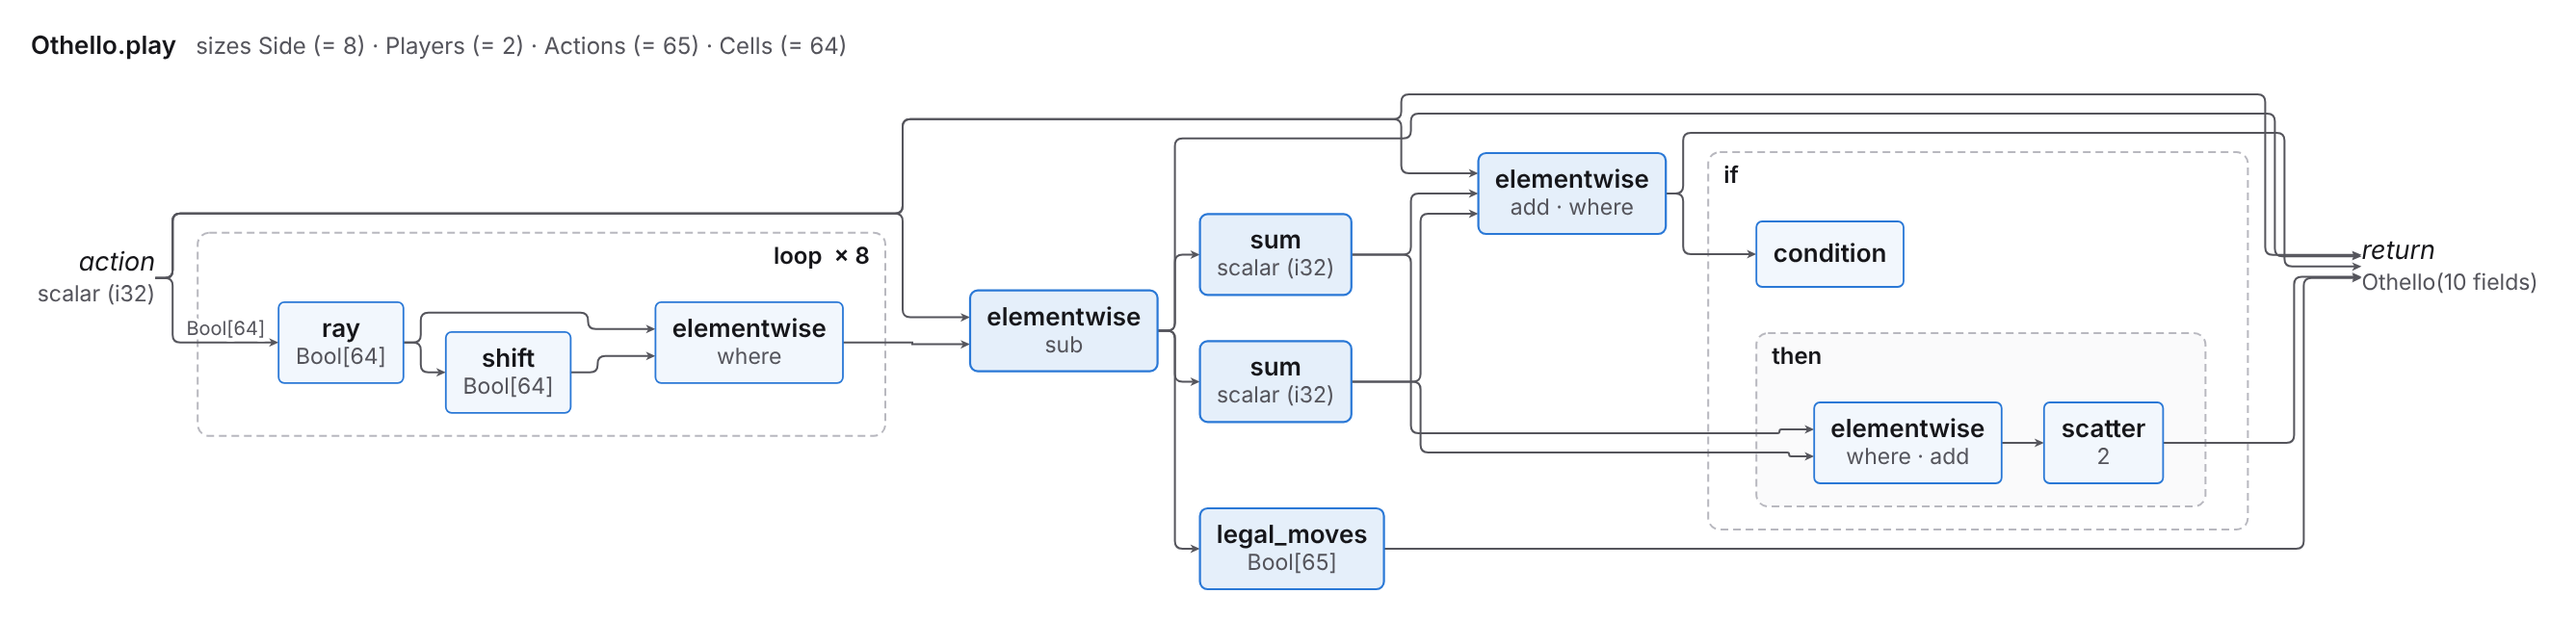

In [11]:
expex.diagram(Othello.play)

`expex.inspect` and `expex.debug.watch` are for models with a `__call__` and a loss; a game
state has neither, so they are not used here.

## A shape error

`Rows` is fixed at 6 (`class Rows(Dim, size=6)`); a board with 5 rows is refused:

In [12]:
try:
    connect_four.line_length(state.board[0, :5], 0, 0, 1, 0)
except expex.ShapeError as e:
    error = e
error

ShapeError: line_length(): argument `board` does not match its annotation.

    declared  board: i32[Rows, Cols]
    received         i32[5, 7]

    axis 0 should be Rows, which is fixed at 6, but is 5.

    line_length(board: i32[Rows, Cols], row: i32[()], col: i32[()], dr: int, dc: int) -> i32[()]
    defined at examples/pgx/connect_four.py:114
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101


## Against the original

`tests/data/pgx_reference.npz` holds 64 random games of each, played by the unmodified Pgx from
fixed keys: the actions, and every field of the state after each step. The ports replay the
same actions from the same keys; `compare.py` counts the (step, game) pairs where a field
differs:

In [13]:
import compare  # examples/pgx/compare.py

reference = dict(np.load(REPO / "tests" / "data" / "pgx_reference.npz"))
for game, mismatches in compare.compare(reference).items():
    print(f"{game:13} {sum(mismatches.values())} mismatches over {', '.join(mismatches)}")

connect_four  0 mismatches over current_player, observation, rewards, terminated, truncated, legal_action_mask, step_count, board
othello       0 mismatches over current_player, observation, rewards, terminated, truncated, legal_action_mask, step_count, board


## Speed

Random games stepped per second, 1024 games x 100 moves, jitted. Timings depend on the
machine. With Pgx installed, `python examples/pgx/compare.py --pgx <pgx checkout>` times both;
the repository's [benchmarks/](../../benchmarks/) report, on CPU (best of 25 rounds, median in
brackets), Connect Four 1.50x (1.61x) faster than Pgx and Othello 1.07x (1.10x).

In [14]:
for game, module in ((ConnectFour, connect_four), (Othello, othello)):
    jax.block_until_ready(module.random_games(jr.key(0), 1024, 100))  # compile
    times = []
    for i in range(3):
        start = time.perf_counter()
        jax.block_until_ready(module.random_games(jr.key(i), 1024, 100))
        times.append(time.perf_counter() - start)
    print(f"{game.__name__:12} {1024 * 100 / np.median(times) / 1e6:5.2f} M steps/s")

ConnectFour   3.19 M steps/s


Othello       0.46 M steps/s
